# **Data Visualization of heart_attack_youth_vs_adult_ in Pakistan**

****Internship**** : **CodeAlpha**

****Name****    :  **Ayyam Ullah Khattak**

****Task****    : **2 Data Visualizaiton**

The Main objective of this Task are to Visualize:


1. Age and gender distribution
2. How many Youth and Adults?
3. Which risk factors are most common?
4. How do risk factors differ between Youth and Adults?
5. Is smoking more prevalent among Youth or Adults?
6. How do BP and cholesterol differ?
7. Does chest pain differ between Youth and Adults?




---


In [ ]:
# import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import matplotlib
print(matplotlib.colors.CSS4_COLORS.keys())

dict_keys(['aliceblue', 'antiquewhite', 'aqua', 'aquamarine', 'azure', 'beige', 'bisque', 'black', 'blanchedalmond', 'blue', 'blueviolet', 'brown', 'burlywood', 'cadetblue', 'chartreuse', 'chocolate', 'coral', 'cornflowerblue', 'cornsilk', 'crimson', 'cyan', 'darkblue', 'darkcyan', 'darkgoldenrod', 'darkgray', 'darkgreen', 'darkgrey', 'darkkhaki', 'darkmagenta', 'darkolivegreen', 'darkorange', 'darkorchid', 'darkred', 'darksalmon', 'darkseagreen', 'darkslateblue', 'darkslategray', 'darkslategrey', 'darkturquoise', 'darkviolet', 'deeppink', 'deepskyblue', 'dimgray', 'dimgrey', 'dodgerblue', 'firebrick', 'floralwhite', 'forestgreen', 'fuchsia', 'gainsboro', 'ghostwhite', 'gold', 'goldenrod', 'gray', 'green', 'greenyellow', 'grey', 'honeydew', 'hotpink', 'indianred', 'indigo', 'ivory', 'khaki', 'lavender', 'lavenderblush', 'lawngreen', 'lemonchiffon', 'lightblue', 'lightcoral', 'lightcyan', 'lightgoldenrodyellow', 'lightgray', 'lightgreen', 'lightgrey', 'lightpink', 'lightsalmon', 'lights

In [ ]:
# Load Dataset
df=pd.read_csv('cleaned_dataset.csv')

In [ ]:
# First Rows of Dataset
df.head(10)

,Age,Gender,Region,BMI,Smoker,Diabetes,Hypertension,Cholesterol_Level,Physical_Activity,Diet,...,Chest_Pain,ECG_Results,Blood_Sugar,Angina,Cardiac_Arrest,Recovery_Status,Medication,Follow_Up,Age_Group,Blood_Sugar_Risk
0,74,Female,Urban,32.1,Yes,Yes,Yes,111.5,Moderate,Healthy,...,No,Abnormal,102.0,No,Yes,Ongoing,Yes,Irregular,Adults,Normal
1,68,Male,Urban,38.3,Yes,Yes,No,276.3,High,Healthy,...,No,Normal,186.9,Yes,No,Deceased,Yes,Regular,Adults,High
2,50,Male,Urban,31.3,Yes,Yes,Yes,134.9,High,Unhealthy,...,Yes,Normal,71.4,No,Yes,Ongoing,No,NaN,Adults,Normal
3,29,Male,Urban,34.0,No,No,No,224.8,High,Healthy,...,No,Normal,191.0,No,No,Recovered,Yes,Regular,Youth,High
4,62,Male,Urban,25.1,No,No,No,128.0,Moderate,Healthy,...,No,Abnormal,184.1,Yes,No,Recovered,No,Irregular,Adults,High
5,67,Male,Urban,18.1,No,No,Yes,157.0,High,Healthy,...,Yes,Normal,147.4,No,Yes,Recovered,No,Irregular,Adults,High
6,62,Female,Urban,33.1,Yes,No,Yes,111.0,Low,Healthy,...,Yes,Normal,173.4,Yes,Yes,Deceased,No,Regular,Adults,High
7,61,Male,Rural,34.0,No,Yes,Yes,149.0,Low,Healthy,...,No,Abnormal,151.8,No,No,Recovered,Yes,NaN,Adults,High
8,25,Female,Rural,39.7,Yes,Yes,Yes,247.4,Moderate,Unhealthy,...,No,Abnormal,166.8,Yes,Yes,Recovered,No,Regular,Youth,High
9,21,Male,Urban,28.4,No,No,Yes,186.3,High,Healthy,...,Yes,Normal,165.3,No,No,Deceased,Yes,Irregular,Youth,High


### **1. Age and gender distribution**

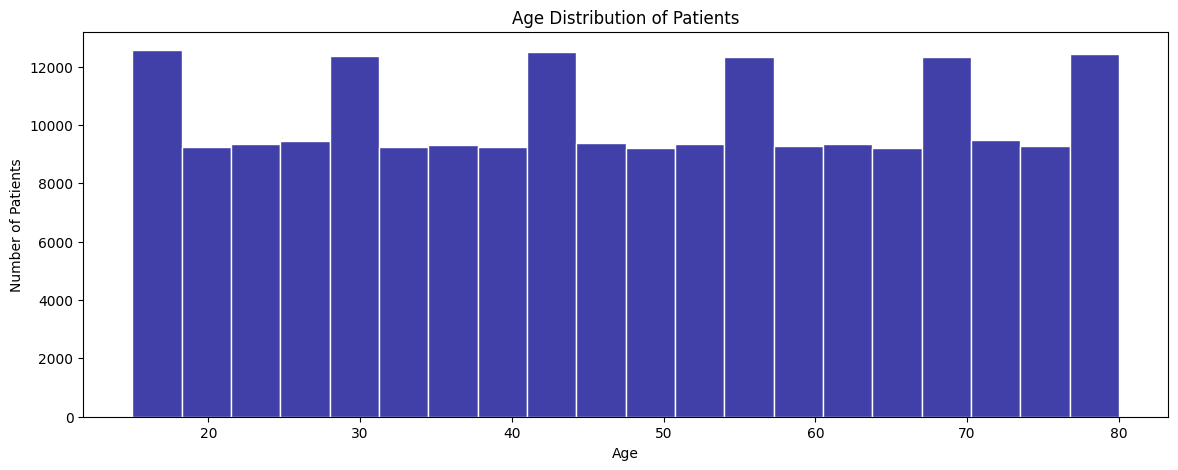

In [ ]:
# Age
figsize = (14, 5)
plt.figure(figsize=figsize)
sns.histplot(data=df, x="Age", bins=20,color="darkblue", edgecolor="white")
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

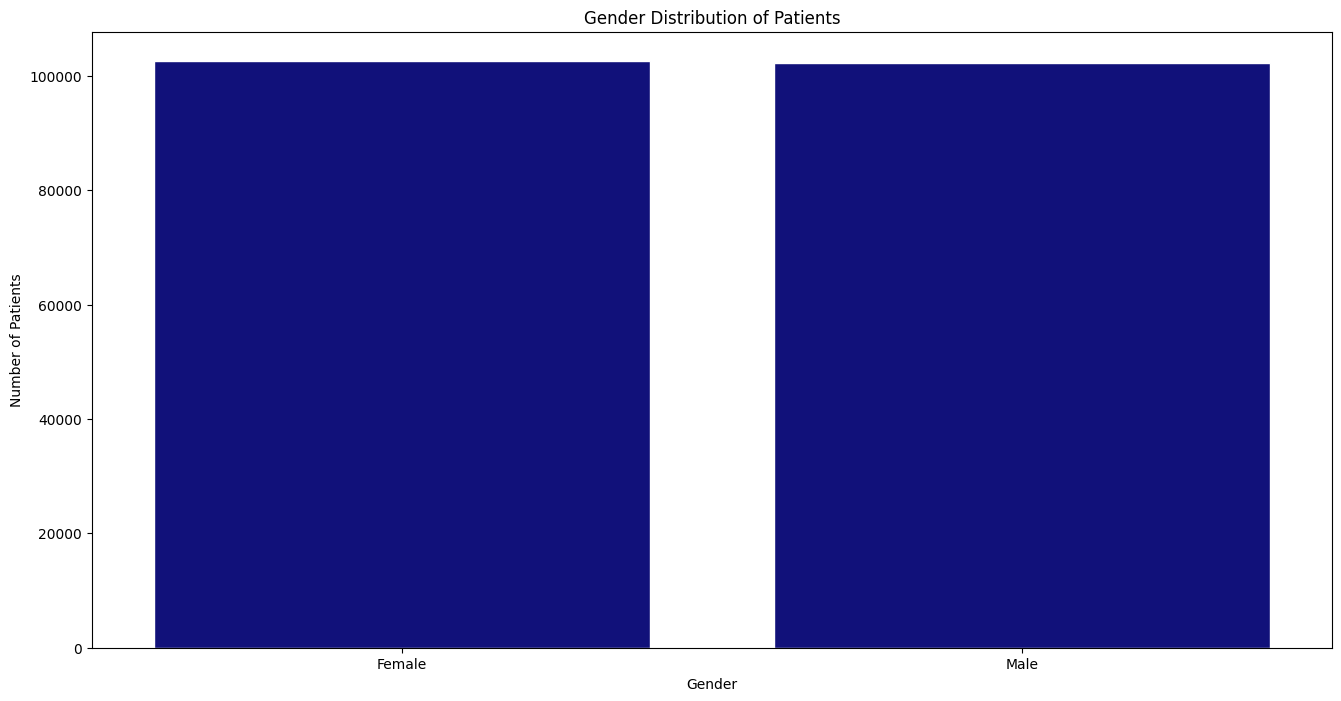

In [ ]:
# Number of Genders
figsize = (16, 8)
plt.figure(figsize=figsize)
sns.countplot(data=df, x="Gender", color="darkblue", edgecolor="white")
plt.title("Gender Distribution of Patients")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()

### **2. How many Youth and Adults?**

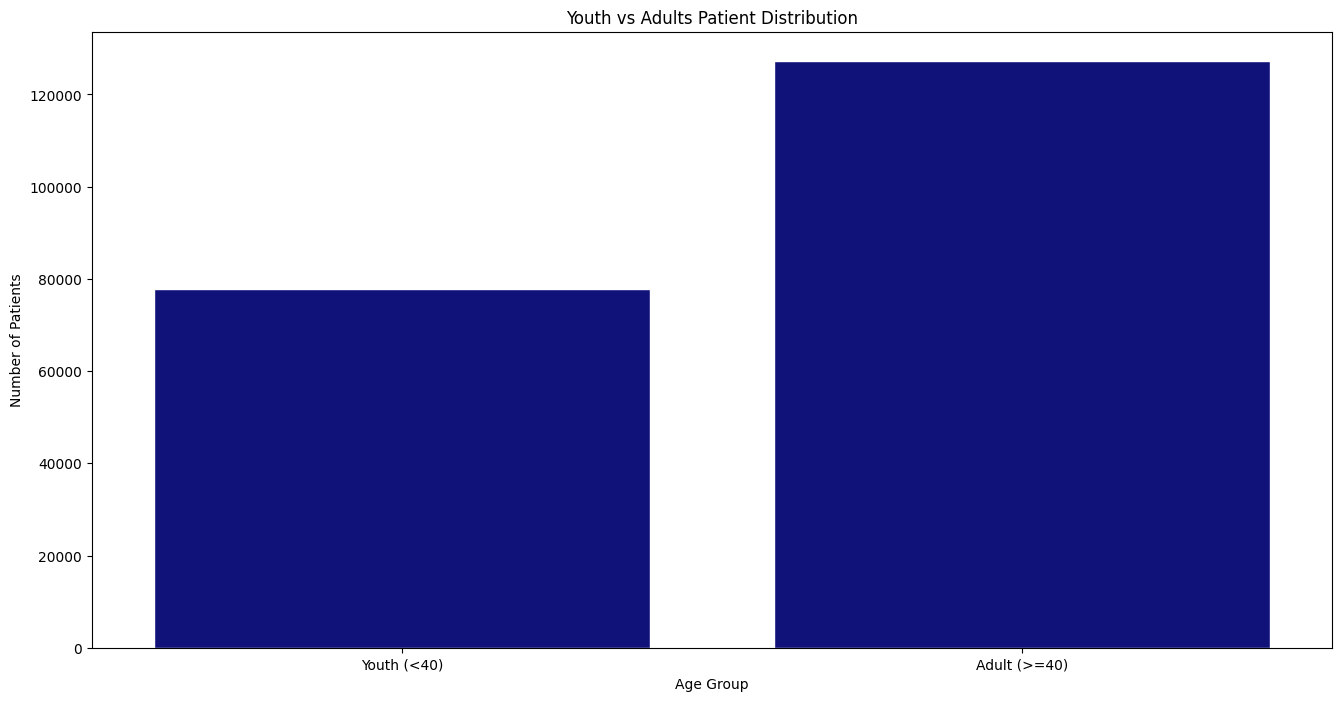

In [ ]:
df['Age_Group'] = df['Age'].apply(lambda x: 'Youth (<40)' if x < 40 else 'Adult (>=40)')

figsize=(16, 8)
plt.figure(figsize=figsize)
sns.countplot(data=df, x="Age_Group", color="darkblue", edgecolor="white", order=['Youth (<40)', 'Adult (>=40)'])
plt.title("Youth vs Adults Patient Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.show()

### **3. Which risk factors are most common?**

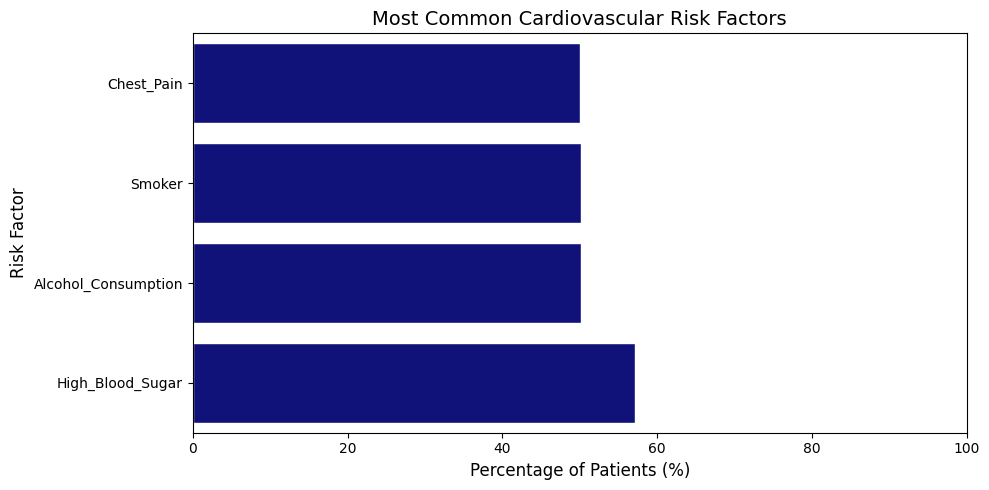

In [ ]:
# Calculate percentages for binary and categorized risk factors
risk_percent = {
    "Smoker": (df["Smoker"] == "Yes").mean() * 100,
    "Alcohol_Consumption": (df["Alcohol_Consumption"] == "Yes").mean() * 100,
    "Chest_Pain": (df["Chest_Pain"] == "Yes").mean() * 100,
    "High_Blood_Sugar": (df["Blood_Sugar_Risk"] == "High").mean() * 100
}

# Convert to DataFrame and sort
risk_df = pd.DataFrame(
    list(risk_percent.items()),
    columns=["Risk_Factor", "Percentage"]
).sort_values("Percentage", ascending=True)

# Plot the corrected values
plt.figure(figsize=(10, 5))
sns.barplot(data=risk_df, x="Percentage", y="Risk_Factor", color="darkblue", edgecolor="white")
plt.title("Most Common Cardiovascular Risk Factors", fontsize=14)
plt.xlabel("Percentage of Patients (%)", fontsize=12)
plt.ylabel("Risk Factor", fontsize=12)
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### **4. How do risk factors differ between Youth and Adults?**

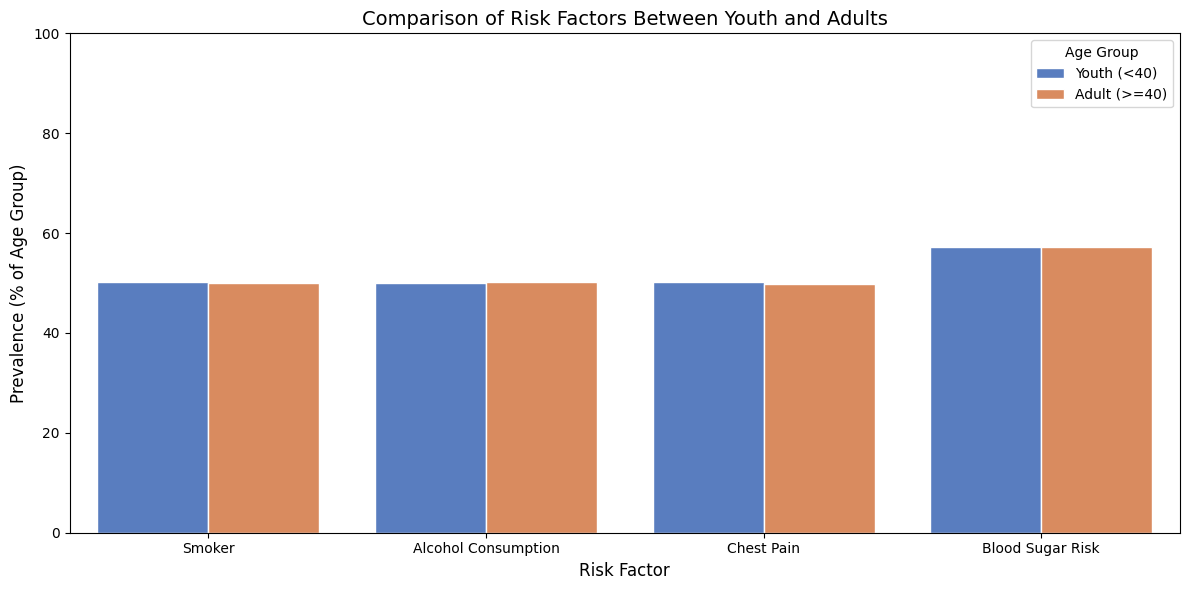

In [ ]:
# Calculate prevalence of each risk factor grouped by Age Group
risk_cols = ['Smoker', 'Alcohol_Consumption', 'Chest_Pain', 'Blood_Sugar_Risk']

# Create a structured DataFrame for plotting
comparison_data = []
for factor in risk_cols:
    for group in ['Youth (<40)', 'Adult (>=40)']:
        sub_df = df[df['Age_Group'] == group]
        if factor == 'Blood_Sugar_Risk':
            percentage = (sub_df[factor] == 'High').mean() * 100
        else:
            percentage = (sub_df[factor] == 'Yes').mean() * 100

        comparison_data.append({
            'Risk Factor': factor.replace('_', ' '),
            'Age Group': group,
            'Prevalence (%)': percentage
        })

comp_df = pd.DataFrame(comparison_data)

# Plot the comparison
plt.figure(figsize=(12, 6))
sns.barplot(data=comp_df, x='Risk Factor', y='Prevalence (%)', hue='Age Group', palette='muted', edgecolor='white')
plt.title("Comparison of Risk Factors Between Youth and Adults", fontsize=14)
plt.ylabel("Prevalence (% of Age Group)", fontsize=12)
plt.xlabel("Risk Factor", fontsize=12)
plt.ylim(0, 100)
plt.legend(title="Age Group")
plt.tight_layout()
plt.show()

### **5. Is smoking more prevalent among Youth or Adults?**

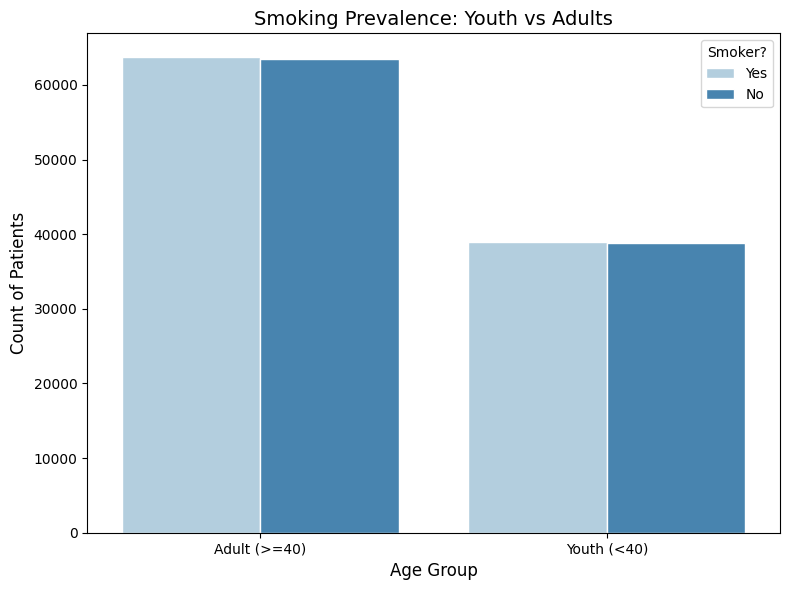

In [ ]:
# Plot smoking prevalence breakdown
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Age_Group', hue='Smoker', palette='Blues', edgecolor='white')
plt.title("Smoking Prevalence: Youth vs Adults", fontsize=14)
plt.xlabel("Age Group", fontsize=12)
plt.ylabel("Count of Patients", fontsize=12)
plt.legend(title="Smoker?")
plt.tight_layout()
plt.show()

### **6. How do BP (Hypertension) and Cholesterol levels differ?**

/tmp/ipykernel_4268/2746258026.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x='Age_Group', y='Cholesterol_Level', palette='Set2')


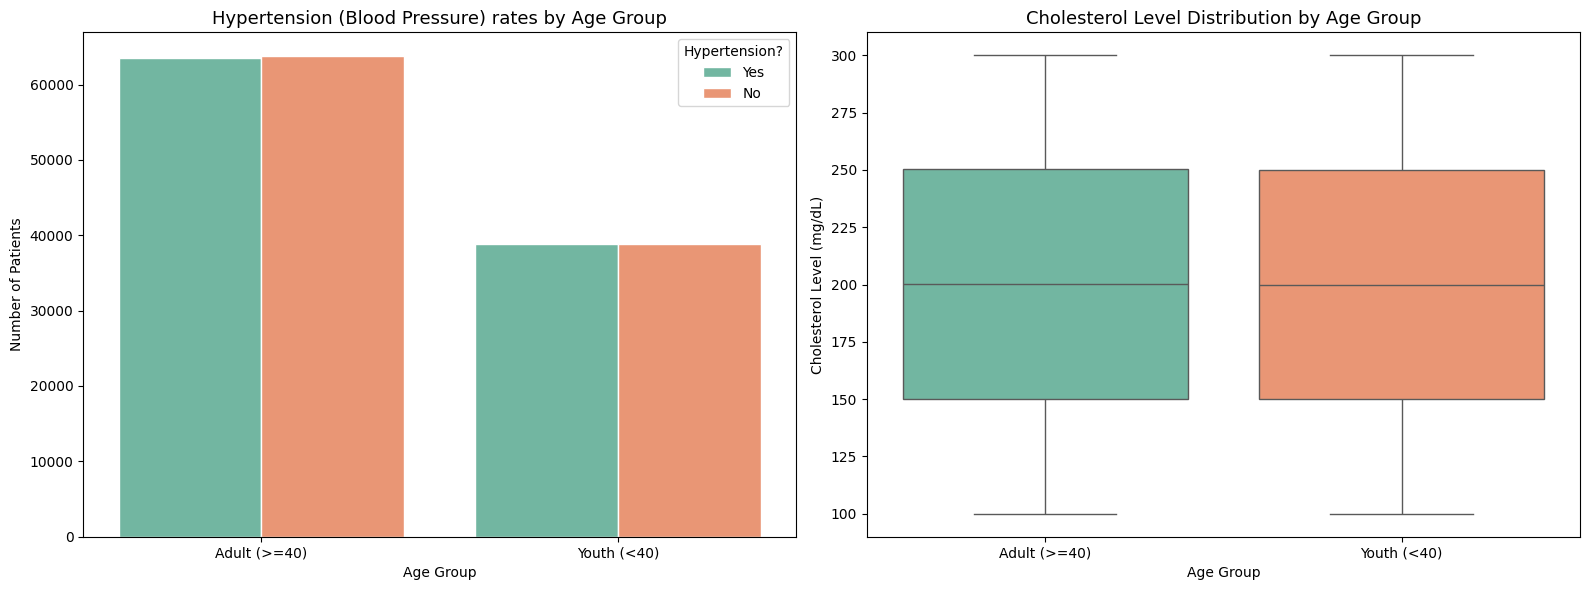

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Hypertension rates across Age Groups
sns.countplot(ax=axes[0], data=df, x='Age_Group', hue='Hypertension', palette='Set2', edgecolor='white')
axes[0].set_title("Hypertension (Blood Pressure) rates by Age Group", fontsize=13)
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Number of Patients")
axes[0].legend(title="Hypertension?")

# Subplot 2: Cholesterol levels distribution by Age Groups
sns.boxplot(ax=axes[1], data=df, x='Age_Group', y='Cholesterol_Level', palette='Set2')
axes[1].set_title("Cholesterol Level Distribution by Age Group", fontsize=13)
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Cholesterol Level (mg/dL)")

plt.tight_layout()
plt.show()

### **7. Does chest pain differ between Youth and Adults?**

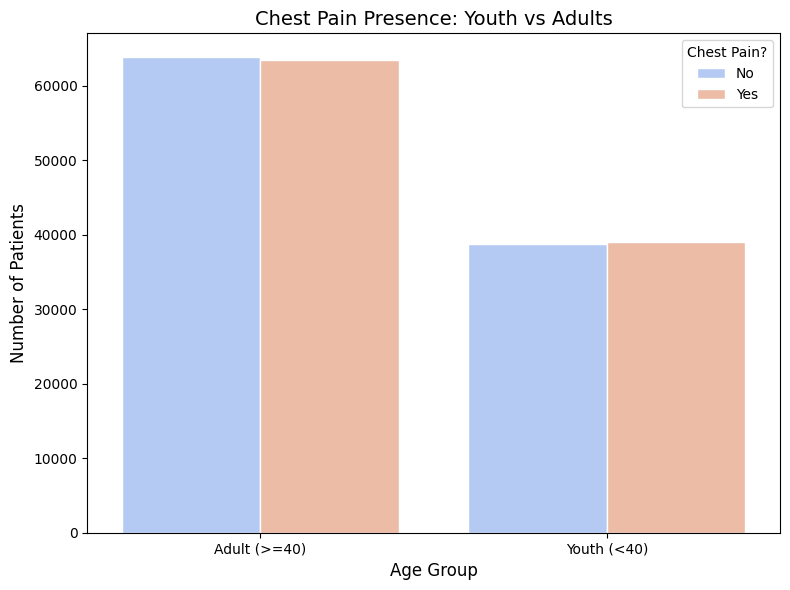

In [ ]:
# Plot chest pain rates across Age Groups
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Age_Group', hue='Chest_Pain', palette='coolwarm', edgecolor='white')
plt.title("Chest Pain Presence: Youth vs Adults", fontsize=14)
plt.xlabel("Age Group", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.legend(title="Chest Pain?")
plt.tight_layout()
plt.show()

## **Key Insights from Data Visualization**

Based on the visual analysis of the Pakistani cardiovascular risk dataset, here are the core findings:

### **1. Age and Gender Distribution**
* The population under study has an extremely balanced gender ratio with nearly equal representation of Male and Female patients.
* The age distribution spans from late teens (15) to late adulthood (80 years old), showing a uniform pattern across the sample.

### **2. Youth vs. Adults Patient Distribution**
* Over **62% of the patients** in this study are classified as **Adults ($≥40$ years old)**, with over 127k individuals.
* **Youth ($<40$ years old)** constitute the remaining segment, representing roughly 77k individuals.

### **3. Most Common Cardiovascular Risk Factors**
* **High Blood Sugar** is the most dominant risk factor, affecting approximately **57.1%** of the entire patient cohort.
* **Smoking** (~50.1%), **Alcohol Consumption** (~50.1%), and **Chest Pain** (~50.0%) are also highly prevalent, each affecting half of the monitored population.

### **4. Risk Factor Differences (Youth vs. Adults)**
* There is an equal rate of occurrence for primary risk factors across age groups. Prevalence of Smoking, Alcohol Consumption, Chest Pain, and High Blood Sugar remains virtually the same regardless of whether a patient is a youth or an adult.

### **5. Smoking Prevalence**
* Smoking habits do not show distinct age boundaries; approximately half of the youth population and half of the adult population are recorded as active smokers.

### **6. Hypertension and Cholesterol Levels**
* **Hypertension:** The ratio of hypertensive patients to non-hypertensive patients is almost identical (~50/50 split) across both Youth and Adult categories.
* **Cholesterol Levels:** The overall distribution, median value (~200 mg/dL), and spread of cholesterol levels are nearly identical for both age cohorts, indicating high cholesterol is a uniform issue in this population.

### **7. Chest Pain Distribution**
* Chest pain complaints are evenly balanced, showing that roughly **50% of both Youth and Adults** experience symptomatic chest pain.